In [1]:
import glob
import regex as re
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report
from matplotlib import pyplot as plt
import mpl_toolkits.axisartist.axislines as axislines

from scipy import stats

import seaborn as sns
sns.set_context('poster')

C:\Users\isen1\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# annotations were run separately for each simulated model
# (results of the earlier mixed pre-/post-election design are in results/mixed_pre_post)
df = pd.concat([
    pd.read_csv(f, low_memory=False)
    for f in sorted(glob.glob('results/pre_election/annotated_GLM-4.7-Flash_*.zst'))
], ignore_index=True)
df

,questionnaire_name,questionnaire_item_id,question,llm_response,logprobs,reasoning,response_type,persona_format,persona_id,sample,model_id,seed,answer
0,openResponse_firstPerson_0_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,Llama-3.1-8B-Instruct,42,Trump
1,openResponse_firstPerson_0_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,Llama-3.1-8B-Instruct,42,Trump
2,openResponse_firstPerson_1_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,1,0,Llama-3.1-8B-Instruct,42,Harris
3,openResponse_firstPerson_1_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I'm going t...",NaN,NaN,openResponse,firstPerson,1,0,Llama-3.1-8B-Instruct,42,Harris
4,openResponse_firstPerson_2_0,1,Will you vote in the 2024 U.S. presidential el...,I cannot predict the outcome of a specific ele...,NaN,NaN,openResponse,firstPerson,2,0,Llama-3.1-8B-Instruct,42,Non-voter
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2434075,jsonResponse_demogrInterview_5068_0,2,Please tell me if you will vote and if so for ...,NaN,NaN,NaN,jsonResponse,demogrInterview,5068,0,Qwen3-VL-8B-Instruct,46,Harris
2434076,jsonResponse_demogrInterview_5069_0,1,Will you vote in the 2024 U.S. presidential el...,NaN,NaN,NaN,jsonResponse,demogrInterview,5069,0,Qwen3-VL-8B-Instruct,46,Harris
2434077,jsonResponse_demogrInterview_5069_0,2,Please tell me if you will vote and if so for ...,NaN,NaN,NaN,jsonResponse,demogrInterview,5069,0,Qwen3-VL-8B-Instruct,46,Harris
2434078,jsonResponse_demogrInterview_5070_0,1,Will you vote in the 2024 U.S. presidential el...,NaN,NaN,NaN,jsonResponse,demogrInterview,5070,0,Qwen3-VL-8B-Instruct,46,Trump


In [3]:
df.columns

Index(['questionnaire_name', 'questionnaire_item_id', 'question',
       'llm_response', 'logprobs', 'reasoning', 'response_type',
       'persona_format', 'persona_id', 'sample', 'model_id', 'seed', 'answer'],
      dtype='object')

In [4]:
df['seed'].unique()

array([42, 43, 44, 45, 46], dtype=int64)

In [5]:
df['regex_answer'] = df.llm_response.str.extract(r'(Trump|Harris|Non-voter)', expand=False)

In [6]:
# add parsing method to specifications
df_regex = df.melt(
    id_vars=[c for c in df.columns if "answer" not in c],
    value_vars=['answer', 'regex_answer'],
    value_name='parsed_answer',
    var_name='parsing_method'
)
df_regex['parsing_method'] = df_regex.parsing_method.replace({'answer': 'LLMjudge', 'regex_answer': 'regex'})

# regex parsing is not applicable to json responses
df_regex = df_regex[
    ~((df_regex.response_type == 'jsonResponse') & (df_regex.parsing_method == 'regex'))
]
df_regex.loc[
    df_regex.response_type == 'jsonResponse',
    'parsing_method'
] = 'jsonParsing'

# convert parsed_answer to str even if regex parsing might have failed
# we define the set of "accepted" labels below to properly handle invalid responses
df_regex['parsed_answer'] = df_regex['parsed_answer'].astype(str)

df_regex

,questionnaire_name,questionnaire_item_id,question,llm_response,logprobs,reasoning,response_type,persona_format,persona_id,sample,model_id,seed,parsing_method,parsed_answer
0,openResponse_firstPerson_0_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,Llama-3.1-8B-Instruct,42,LLMjudge,Trump
1,openResponse_firstPerson_0_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,Llama-3.1-8B-Instruct,42,LLMjudge,Trump
2,openResponse_firstPerson_1_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,1,0,Llama-3.1-8B-Instruct,42,LLMjudge,Harris
3,openResponse_firstPerson_1_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I'm going t...",NaN,NaN,openResponse,firstPerson,1,0,Llama-3.1-8B-Instruct,42,LLMjudge,Harris
4,openResponse_firstPerson_2_0,1,Will you vote in the 2024 U.S. presidential el...,I cannot predict the outcome of a specific ele...,NaN,NaN,openResponse,firstPerson,2,0,Llama-3.1-8B-Instruct,42,LLMjudge,Non-voter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4665315,openResponse_demogrInterview_5068_0,2,Please tell me if you will vote and if so for ...,"I will vote for Harris.\n\nAs a White, 69-year...",NaN,NaN,openResponse,demogrInterview,5068,0,Qwen3-VL-8B-Instruct,46,regex,Harris
4665316,openResponse_demogrInterview_5069_0,1,Will you vote in the 2024 U.S. presidential el...,Harris.\n\nAs a 28-year-old Black male from Ne...,NaN,NaN,openResponse,demogrInterview,5069,0,Qwen3-VL-8B-Instruct,46,regex,Harris
4665317,openResponse_demogrInterview_5069_0,2,Please tell me if you will vote and if so for ...,Harris. \n\nAs a young Black male from New Jer...,NaN,NaN,openResponse,demogrInterview,5069,0,Qwen3-VL-8B-Instruct,46,regex,Harris
4665318,openResponse_demogrInterview_5070_0,1,Will you vote in the 2024 U.S. presidential el...,Trump\n\n*Note: As a political scientist predi...,NaN,NaN,openResponse,demogrInterview,5070,0,Qwen3-VL-8B-Instruct,46,regex,Trump


In [7]:
anes_df = pd.read_csv('data/2024_anes_pre-election_preprocessed.csv', index_col=0).reset_index(names='ANES_index')
anes_df['age_bracket'] = (anes_df.age // 10) * 10
anes_df

,ANES_index,anes_id,mode,pre_weight,post_weight,age,political_attention,race,ideology,party,attend_church,gender,campaign_interest,state,vote_intent_summary,turnout_likelihood,reported_turnout,reported_vote,vote_choice,age_bracket
0,0,140001,2,0.716602,0.710865,50.0,pay attention to what's going on in government...,Hispanic,conservative,a strong Republican,True,male,very much,Oklahoma,21,2,1,Trump,Trump,50.0
1,2,140003,2,0.780178,0.808992,44.0,pay attention to what's going on in government...,White,liberal,a strong Democrat,False,female,very much,Virginia,20,2,1,Harris,Harris,40.0
2,3,140004,2,0.268988,0.291740,45.0,pay attention to what's going on in government...,Asian,NaN,a weak Republican,True,male,somewhat,California,21,4,0,Non-voter,Trump,40.0
3,4,140005,2,0.244306,0.222012,80.0,pay attention to what's going on in government...,White,moderate,an independent who leans Republican,False,male,somewhat,Colorado,21,3,1,Trump,Trump,80.0
4,5,140006,2,0.498597,0.472275,75.0,always pay attention to what's going on in gov...,White,moderate,an independent who leans Democratic,False,female,very much,Texas,20,2,0,Non-voter,Harris,70.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5066,5515,399579,1,0.115966,0.075758,80.0,pay attention to what's going on in government...,Hispanic,slightly liberal,an independent who leans Democratic,False,female,very much,Colorado,20,2,1,Harris,Harris,80.0
5067,5516,399764,1,0.193087,NaN,NaN,pay attention to what's going on in government...,NaN,moderate,an independent,True,female,not much,California,-2,5,-2,NaN,Non-voter,NaN
5068,5517,399815,1,2.910370,1.797863,69.0,always pay attention to what's going on in gov...,White,slightly liberal,a weak Democrat,True,female,very much,Minnesota,20,2,1,Harris,Harris,60.0
5069,5519,399841,4,2.635201,2.255936,28.0,pay attention to what's going on in government...,Black,extremely liberal,a strong Democrat,False,male,very much,New Jersey,20,2,1,Harris,Harris,20.0


In [8]:
comb_df = pd.merge(
    left = df_regex,
    right = anes_df,
    left_on = 'persona_id',
    right_index = True,
    how = 'left'
)
comb_df.head()

,questionnaire_name,questionnaire_item_id,question,llm_response,logprobs,reasoning,response_type,persona_format,persona_id,sample,...,attend_church,gender,campaign_interest,state,vote_intent_summary,turnout_likelihood,reported_turnout,reported_vote,vote_choice,age_bracket
0,openResponse_firstPerson_0_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,...,True,male,very much,Oklahoma,21,2,1,Trump,Trump,50.0
1,openResponse_firstPerson_0_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,0,0,...,True,male,very much,Oklahoma,21,2,1,Trump,Trump,50.0
2,openResponse_firstPerson_1_0,1,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,openResponse,firstPerson,1,0,...,False,female,very much,Virginia,20,2,1,Harris,Harris,40.0
3,openResponse_firstPerson_1_0,2,Please tell me if you will vote and if so for ...,"Based on the information provided, I'm going t...",NaN,NaN,openResponse,firstPerson,1,0,...,False,female,very much,Virginia,20,2,1,Harris,Harris,40.0
4,openResponse_firstPerson_2_0,1,Will you vote in the 2024 U.S. presidential el...,I cannot predict the outcome of a specific ele...,NaN,NaN,openResponse,firstPerson,2,0,...,True,male,somewhat,California,21,4,0,Non-voter,Trump,40.0


In [9]:
comb_df.columns

Index(['questionnaire_name', 'questionnaire_item_id', 'question',
       'llm_response', 'logprobs', 'reasoning', 'response_type',
       'persona_format', 'persona_id', 'sample', 'model_id', 'seed',
       'parsing_method', 'parsed_answer', 'ANES_index', 'anes_id', 'mode',
       'pre_weight', 'post_weight', 'age', 'political_attention', 'race',
       'ideology', 'party', 'attend_church', 'gender', 'campaign_interest',
       'state', 'vote_intent_summary', 'turnout_likelihood',
       'reported_turnout', 'reported_vote', 'vote_choice', 'age_bracket'],
      dtype='object')

In [10]:
### Calculate metrics for each simulation specification

specification_cols = [
    'questionnaire_item_id',
    'response_type',
    'persona_format',
    'sample',
    'model_id',
    'parsing_method'
]

demographic_cols = [
    'age_bracket',
    'political_attention',
    'race',
    'ideology',
    'party',
    'attend_church',
    'gender',
    'campaign_interest',
    'state'
]

labels = ['Trump', 'Harris', 'Non-voter']
subgroups_of_interest = ['gender', 'ideology']

In [11]:
comb_df.columns

Index(['questionnaire_name', 'questionnaire_item_id', 'question',
       'llm_response', 'logprobs', 'reasoning', 'response_type',
       'persona_format', 'persona_id', 'sample', 'model_id', 'seed',
       'parsing_method', 'parsed_answer', 'ANES_index', 'anes_id', 'mode',
       'pre_weight', 'post_weight', 'age', 'political_attention', 'race',
       'ideology', 'party', 'attend_church', 'gender', 'campaign_interest',
       'state', 'vote_intent_summary', 'turnout_likelihood',
       'reported_turnout', 'reported_vote', 'vote_choice', 'age_bracket'],
      dtype='object')

In [12]:
comb_df['correct'] = [1 if row['vote_choice'] == row['parsed_answer'] else 0 for _, row in comb_df.iterrows()]

In [13]:
comb_df.groupby('correct').size()/len(comb_df)#.sum()

correct
0    0.359918
1    0.640082
dtype: float64

In [14]:
print(classification_report(comb_df['vote_choice'], comb_df['parsed_answer'], 
                           zero_division=0))

              precision    recall  f1-score   support

      Harris       0.71      0.67      0.69   1771200
   Non-voter       0.26      0.09      0.14    419040
       Trump       0.62      0.76      0.68   1460880
         nan       0.00      0.00      0.00         0

    accuracy                           0.64   3651120
   macro avg       0.40      0.38      0.38   3651120
weighted avg       0.62      0.64      0.62   3651120



In [15]:
plot_df = comb_df.copy()

In [16]:
plot_df['Survey Question'] = plot_df.questionnaire_item_id.replace({1: 'Version 1', 2: 'Version 2'})
plot_df['response_type'] = plot_df.response_type.replace({'jsonResponse': 'JSON structured output', 'openResponse': 'open-ended response'})
plot_df['parsing_method'] = plot_df.parsing_method.replace({'jsonParsing': 'JSON parsing', 'regex': 'regex parsing', 'LLMjudge': 'LLM-as-a-judge'})
plot_df['Persona Information'] = plot_df.persona_format.apply(lambda x:'demographic only' if 'demogr' in x else 'demographics & attitudes')
plot_df['Persona Format'] = plot_df.persona_format.apply(lambda x:'direct' if 'Person' in x else 'interview')

plot_df = plot_df.drop(columns=['questionnaire_item_id', 'persona_format', 'sample'])
plot_df = plot_df.rename(columns={
    'response_type': 'Output Generation',
    'model_id': 'LLM model ID',
    'parsing_method': 'Output Parsing',
})

In [17]:
indep_vars = ['Output Generation', 'LLM model ID', 'Output Parsing', 'Survey Question', 'Persona Information',
       'Persona Format']

In [18]:
plot_df = plot_df.rename(columns={i : '_'.join(i.split()) for i in indep_vars})
indep_vars = ['_'.join(i.split()) for i in indep_vars]
plot_df[indep_vars]

,Output_Generation,LLM_model_ID,Output_Parsing,Survey_Question,Persona_Information,Persona_Format
0,open-ended response,Llama-3.1-8B-Instruct,LLM-as-a-judge,Version 1,demographics & attitudes,direct
1,open-ended response,Llama-3.1-8B-Instruct,LLM-as-a-judge,Version 2,demographics & attitudes,direct
2,open-ended response,Llama-3.1-8B-Instruct,LLM-as-a-judge,Version 1,demographics & attitudes,direct
3,open-ended response,Llama-3.1-8B-Instruct,LLM-as-a-judge,Version 2,demographics & attitudes,direct
4,open-ended response,Llama-3.1-8B-Instruct,LLM-as-a-judge,Version 1,demographics & attitudes,direct
...,...,...,...,...,...,...
4665315,open-ended response,Qwen3-VL-8B-Instruct,regex parsing,Version 2,demographic only,interview
4665316,open-ended response,Qwen3-VL-8B-Instruct,regex parsing,Version 1,demographic only,interview
4665317,open-ended response,Qwen3-VL-8B-Instruct,regex parsing,Version 2,demographic only,interview
4665318,open-ended response,Qwen3-VL-8B-Instruct,regex parsing,Version 1,demographic only,interview


In [19]:
for var in indep_vars:
    print(var)
    print(plot_df[var].unique())

Output_Generation
['open-ended response' 'JSON structured output']
LLM_model_ID
['Llama-3.1-8B-Instruct' 'Llama-3.3-70B-Instruct' 'Olmo-3-7B-Instruct'
 'Olmo-3.1-32B-Instruct' 'Qwen3-VL-30B-A3B-Instruct'
 'Qwen3-VL-8B-Instruct']
Output_Parsing
['LLM-as-a-judge' 'JSON parsing' 'regex parsing']
Survey_Question
['Version 1' 'Version 2']
Persona_Information
['demographics & attitudes' 'demographic only']
Persona_Format
['direct' 'interview']


In [20]:
og_dict = {'JSON structured output': 'JSON',
           'open-ended response' : 'free-text'}
model_dict = {'Llama-3.1-8B-Instruct': 'Llama-8B',
              'Llama-3.3-70B-Instruct': 'Llama-70B',
              'Olmo-3-7B-Instruct': 'Olmo-7B',
              'Olmo-3.1-32B-Instruct': 'Olmo-32B',
              'Qwen3-VL-30B-A3B-Instruct': 'Qwen-30B',
              'Qwen3-VL-8B-Instruct': 'Qwen-8B'
             }
op_dict = {'JSON parsing': 'JSON_parsing',
           'LLM-as-a-judge': 'LLM judge',
           'regex parsing': 'regex'}

sq_dict = {'Version 1' : 'v1',
           'Version 2' : 'v2'}

pi_dict = {'demographic only': 'demo',
      'demographics & attitudes' : 'demo+att'}

pf_dict = {'direct' : 'direct',
           'interview' : 'interview'}

In [21]:
### rename everything

og = []
models = []
op = []
sq = []
pi = []
pf = []

for _, row in plot_df.iterrows():
    og.append(og_dict[row['Output_Generation']])
    models.append(model_dict[row['LLM_model_ID']])
    op.append(op_dict[row['Output_Parsing']])
    sq.append(sq_dict[row['Survey_Question']])
    pi.append(pi_dict[row['Persona_Information']])
    pf.append(pf_dict[row['Persona_Format']])
    
plot_df['Output_Generation'] = og
plot_df['LLM_model_ID'] = models
plot_df['Output_Parsing'] = op
plot_df['Survey_Question'] = sq
plot_df['Persona_Information'] = pi
plot_df['Persona_Format'] = pf

In [22]:
### combine persona_format and persona_info into persona construction
plot_df['Persona'] = plot_df['Persona_Information'] + ' (' + plot_df['Persona_Format']  + ')'

In [23]:
plot_df = plot_df.rename(columns = {'Output_Generation': 'Inference',
                                    'LLM_model_ID': 'LLM',
                                    'Output_Parsing': 'Behavior_Proc',
                                    'Survey_Question': 'Task',
                                    })
indep_vars = ['Inference',
'LLM',
    'Behavior_Proc',
    'Task',
    'Persona'
    ]

In [24]:
plot_df.isna().sum()

questionnaire_name           0
question                     0
llm_response           1217040
logprobs               3651120
reasoning              3651110
Inference                    0
persona_id                   0
LLM                          0
seed                         0
Behavior_Proc                0
parsed_answer                0
ANES_index                   0
anes_id                      0
mode                         0
pre_weight                   0
post_weight             352800
age                     169920
political_attention       1440
race                     40320
ideology                498240
party                    18720
attend_church           177120
gender                   26640
campaign_interest       158400
state                        0
vote_intent_summary          0
turnout_likelihood           0
reported_turnout             0
reported_vote           414000
vote_choice                  0
age_bracket             169920
correct                      0
Task    

In [25]:
plot_df.groupby(['LLM', 'parsed_answer']).size().unstack()

parsed_answer,Harris,Non-voter,Trump,nan
LLM,,,,
Llama-70B,301002,3312,304189,17
Llama-8B,265873,28147,304086,10414
Olmo-32B,275594,62851,255203,14872
Olmo-7B,216631,38711,348567,4611
Qwen-30B,334658,11087,262543,232
Qwen-8B,270729,6037,331753,1


In [26]:
# Response Generation (Inference) and Response Processing (Behavior_Proc) are
# structurally confounded: JSON parsing only ever occurs with JSON-structured
# output, and regex/LLM-judge parsing only ever occur with free-text output.
# Modeling them as two separate main effects makes the design matrix
# rank-deficient (the "covariance of constraints does not have full rank"
# warning) and the individual coefficients are not uniquely identified. Merge
# them into a single factor, the same way Persona_Information + Persona_Format
# were merged into Persona above.
plot_df['Response_Handling'] = plot_df['Inference'] + ' + ' + plot_df['Behavior_Proc']

In [27]:
design_indep_vars = ['Response_Handling', 'LLM', 'Task', 'Persona']
subgroup_indep_vars = ['age',
       'political_attention', 'race', 'ideology', 'party', 'attend_church',
       'gender', 'campaign_interest', 'state', 'turnout_likelihood']
dep_vars = ['correct']

In [28]:
plot_df.columns

Index(['questionnaire_name', 'question', 'llm_response', 'logprobs',
       'reasoning', 'Inference', 'persona_id', 'LLM', 'seed', 'Behavior_Proc',
       'parsed_answer', 'ANES_index', 'anes_id', 'mode', 'pre_weight',
       'post_weight', 'age', 'political_attention', 'race', 'ideology',
       'party', 'attend_church', 'gender', 'campaign_interest', 'state',
       'vote_intent_summary', 'turnout_likelihood', 'reported_turnout',
       'reported_vote', 'vote_choice', 'age_bracket', 'correct', 'Task',
       'Persona_Information', 'Persona_Format', 'Persona',
       'Response_Handling'],
      dtype='object')

In [29]:
plot_df[design_indep_vars + subgroup_indep_vars + dep_vars]

,Response_Handling,LLM,Task,Persona,age,political_attention,race,ideology,party,attend_church,gender,campaign_interest,state,turnout_likelihood,correct
0,free-text + LLM judge,Llama-8B,v1,demo+att (direct),50.0,pay attention to what's going on in government...,Hispanic,conservative,a strong Republican,True,male,very much,Oklahoma,2,1
1,free-text + LLM judge,Llama-8B,v2,demo+att (direct),50.0,pay attention to what's going on in government...,Hispanic,conservative,a strong Republican,True,male,very much,Oklahoma,2,1
2,free-text + LLM judge,Llama-8B,v1,demo+att (direct),44.0,pay attention to what's going on in government...,White,liberal,a strong Democrat,False,female,very much,Virginia,2,1
3,free-text + LLM judge,Llama-8B,v2,demo+att (direct),44.0,pay attention to what's going on in government...,White,liberal,a strong Democrat,False,female,very much,Virginia,2,1
4,free-text + LLM judge,Llama-8B,v1,demo+att (direct),45.0,pay attention to what's going on in government...,Asian,NaN,a weak Republican,True,male,somewhat,California,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4665315,free-text + regex,Qwen-8B,v2,demo (interview),69.0,always pay attention to what's going on in gov...,White,slightly liberal,a weak Democrat,True,female,very much,Minnesota,2,1
4665316,free-text + regex,Qwen-8B,v1,demo (interview),28.0,pay attention to what's going on in government...,Black,extremely liberal,a strong Democrat,False,male,very much,New Jersey,2,1
4665317,free-text + regex,Qwen-8B,v2,demo (interview),28.0,pay attention to what's going on in government...,Black,extremely liberal,a strong Democrat,False,male,very much,New Jersey,2,1
4665318,free-text + regex,Qwen-8B,v1,demo (interview),37.0,pay attention to what's going on in government...,White,slightly conservative,a weak Republican,True,female,somewhat,Tennessee,3,1


## descriptive results

- overall performance and best-performing design choice variant
- difference between best and worst design configuration
- is the best configuration the same between both metrics
- rank correlation between tvd and f1 rankings of configs

In [30]:
metrics_for_table = ['correct']

In [31]:
mean = {}
std = {}
for metric in metrics_for_table:
    mean[metric] = {}
    std[metric] = {}
    for var in indep_vars:
        mean[metric][var] = dict(plot_df.groupby(var).mean(numeric_only = True)[metric])
        std[metric][var] = dict(plot_df.groupby(var).std(numeric_only = True)[metric])

In [32]:
table = {}
for metric in metrics_for_table:
    df_rows = []
    for var in mean[metric]:
        for var2 in mean[metric][var]:
            num = str(mean[metric][var][var2].round(3)) + ' \u00B1 ' + str(std[metric][var][var2].round(2))
            df_rows.append([var, var2, num])
    
    num = str(plot_df.mean(numeric_only = True)[metric].round(3)) + ' \u00B1 ' \
          + str(plot_df.std(numeric_only = True)[metric].round(2))
    df_rows.append(['Overall', 'Overall', num])
    table[metric] = pd.DataFrame(df_rows)
    table[metric].columns = ['Design Choice', 'Variant', '%s' %(metric)]
    
table_df = table[metrics_for_table[0]]
for metric in metrics_for_table[1:]:
    table_df = table_df.merge(table[metric])

In [33]:
table_df

,Design Choice,Variant,correct
0,Inference,JSON,0.654 ± 0.48
1,Inference,free-text,0.633 ± 0.48
2,LLM,Llama-70B,0.676 ± 0.47
3,LLM,Llama-8B,0.619 ± 0.49
4,LLM,Olmo-32B,0.629 ± 0.48
5,LLM,Olmo-7B,0.584 ± 0.49
6,LLM,Qwen-30B,0.676 ± 0.47
7,LLM,Qwen-8B,0.656 ± 0.48
8,Behavior_Proc,JSON_parsing,0.654 ± 0.48
9,Behavior_Proc,LLM judge,0.636 ± 0.48


In [34]:
print(table_df.to_latex())

\begin{tabular}{llll}
\toprule
 & Design Choice & Variant & correct \\
\midrule
0 & Inference & JSON & 0.654 ± 0.48 \\
1 & Inference & free-text & 0.633 ± 0.48 \\
2 & LLM & Llama-70B & 0.676 ± 0.47 \\
3 & LLM & Llama-8B & 0.619 ± 0.49 \\
4 & LLM & Olmo-32B & 0.629 ± 0.48 \\
5 & LLM & Olmo-7B & 0.584 ± 0.49 \\
6 & LLM & Qwen-30B & 0.676 ± 0.47 \\
7 & LLM & Qwen-8B & 0.656 ± 0.48 \\
8 & Behavior_Proc & JSON_parsing & 0.654 ± 0.48 \\
9 & Behavior_Proc & LLM judge & 0.636 ± 0.48 \\
10 & Behavior_Proc & regex & 0.63 ± 0.48 \\
11 & Task & v1 & 0.641 ± 0.48 \\
12 & Task & v2 & 0.639 ± 0.48 \\
13 & Persona & demo (direct) & 0.502 ± 0.5 \\
14 & Persona & demo (interview) & 0.498 ± 0.5 \\
15 & Persona & demo+att (direct) & 0.791 ± 0.41 \\
16 & Persona & demo+att (interview) & 0.77 ± 0.42 \\
17 & Overall & Overall & 0.64 ± 0.48 \\
\bottomrule
\end{tabular}



In [35]:
# best and worst configuration
best = {}
worst = {}
for metric in metrics_for_table:
    if metric == 'weighted_tvd':
        best[metric+'_config_id'] = plot_df.sort_values(metric).index[0]
        worst[metric+'_config_id'] = plot_df.sort_values(metric).index[-1]
        best[metric+'_config'] = plot_df.sort_values(metric)[indep_vars].iloc[0]
        worst[metric+'_config'] = plot_df.sort_values(metric)[indep_vars].iloc[-1]
        best[metric+'_val'] = plot_df.sort_values(metric)[metric].iloc[0]
        worst[metric+'_val'] = plot_df.sort_values(metric)[metric].iloc[-1]
    else:
        best[metric+'_config_id'] = plot_df.sort_values(metric, ascending=False).index[0]
        worst[metric+'_config_id'] = plot_df.sort_values(metric, ascending=False).index[-1]
        best[metric+'_config'] = plot_df.sort_values(metric, ascending=False)[indep_vars].iloc[0]
        worst[metric+'_config'] = plot_df.sort_values(metric, ascending=False)[indep_vars].iloc[-1]
        best[metric+'_val'] = plot_df.sort_values(metric, ascending=False)[metric].iloc[0]
        worst[metric+'_val'] = plot_df.sort_values(metric, ascending=False)[metric].iloc[-1]

In [36]:
best

{'correct_config_id': 0,
 'correct_config': Inference                free-text
 LLM                       Llama-8B
 Behavior_Proc            LLM judge
 Task                            v1
 Persona          demo+att (direct)
 Name: 0, dtype: object,
 'correct_val': 1}

In [37]:
worst

{'correct_config_id': 2541799,
 'correct_config': Inference            free-text
 LLM                   Llama-8B
 Behavior_Proc            regex
 Task                        v2
 Persona          demo (direct)
 Name: 2541799, dtype: object,
 'correct_val': 0}

In [38]:
plot_df

,questionnaire_name,question,llm_response,logprobs,reasoning,Inference,persona_id,LLM,seed,Behavior_Proc,...,reported_turnout,reported_vote,vote_choice,age_bracket,correct,Task,Persona_Information,Persona_Format,Persona,Response_Handling
0,openResponse_firstPerson_0_0,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,free-text,0,Llama-8B,42,LLM judge,...,1,Trump,Trump,50.0,1,v1,demo+att,direct,demo+att (direct),free-text + LLM judge
1,openResponse_firstPerson_0_0,Please tell me if you will vote and if so for ...,"Based on the information provided, I would pre...",NaN,NaN,free-text,0,Llama-8B,42,LLM judge,...,1,Trump,Trump,50.0,1,v2,demo+att,direct,demo+att (direct),free-text + LLM judge
2,openResponse_firstPerson_1_0,Will you vote in the 2024 U.S. presidential el...,"Based on the information provided, I would pre...",NaN,NaN,free-text,1,Llama-8B,42,LLM judge,...,1,Harris,Harris,40.0,1,v1,demo+att,direct,demo+att (direct),free-text + LLM judge
3,openResponse_firstPerson_1_0,Please tell me if you will vote and if so for ...,"Based on the information provided, I'm going t...",NaN,NaN,free-text,1,Llama-8B,42,LLM judge,...,1,Harris,Harris,40.0,1,v2,demo+att,direct,demo+att (direct),free-text + LLM judge
4,openResponse_firstPerson_2_0,Will you vote in the 2024 U.S. presidential el...,I cannot predict the outcome of a specific ele...,NaN,NaN,free-text,2,Llama-8B,42,LLM judge,...,0,Non-voter,Trump,40.0,0,v1,demo+att,direct,demo+att (direct),free-text + LLM judge
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4665315,openResponse_demogrInterview_5068_0,Please tell me if you will vote and if so for ...,"I will vote for Harris.\n\nAs a White, 69-year...",NaN,NaN,free-text,5068,Qwen-8B,46,regex,...,1,Harris,Harris,60.0,1,v2,demo,interview,demo (interview),free-text + regex
4665316,openResponse_demogrInterview_5069_0,Will you vote in the 2024 U.S. presidential el...,Harris.\n\nAs a 28-year-old Black male from Ne...,NaN,NaN,free-text,5069,Qwen-8B,46,regex,...,1,Harris,Harris,20.0,1,v1,demo,interview,demo (interview),free-text + regex
4665317,openResponse_demogrInterview_5069_0,Please tell me if you will vote and if so for ...,Harris. \n\nAs a young Black male from New Jer...,NaN,NaN,free-text,5069,Qwen-8B,46,regex,...,1,Harris,Harris,20.0,1,v2,demo,interview,demo (interview),free-text + regex
4665318,openResponse_demogrInterview_5070_0,Will you vote in the 2024 U.S. presidential el...,Trump\n\n*Note: As a political scientist predi...,NaN,NaN,free-text,5070,Qwen-8B,46,regex,...,1,Trump,Trump,30.0,1,v1,demo,interview,demo (interview),free-text + regex


In [39]:
# plot the vote choice distributions for different subgroups

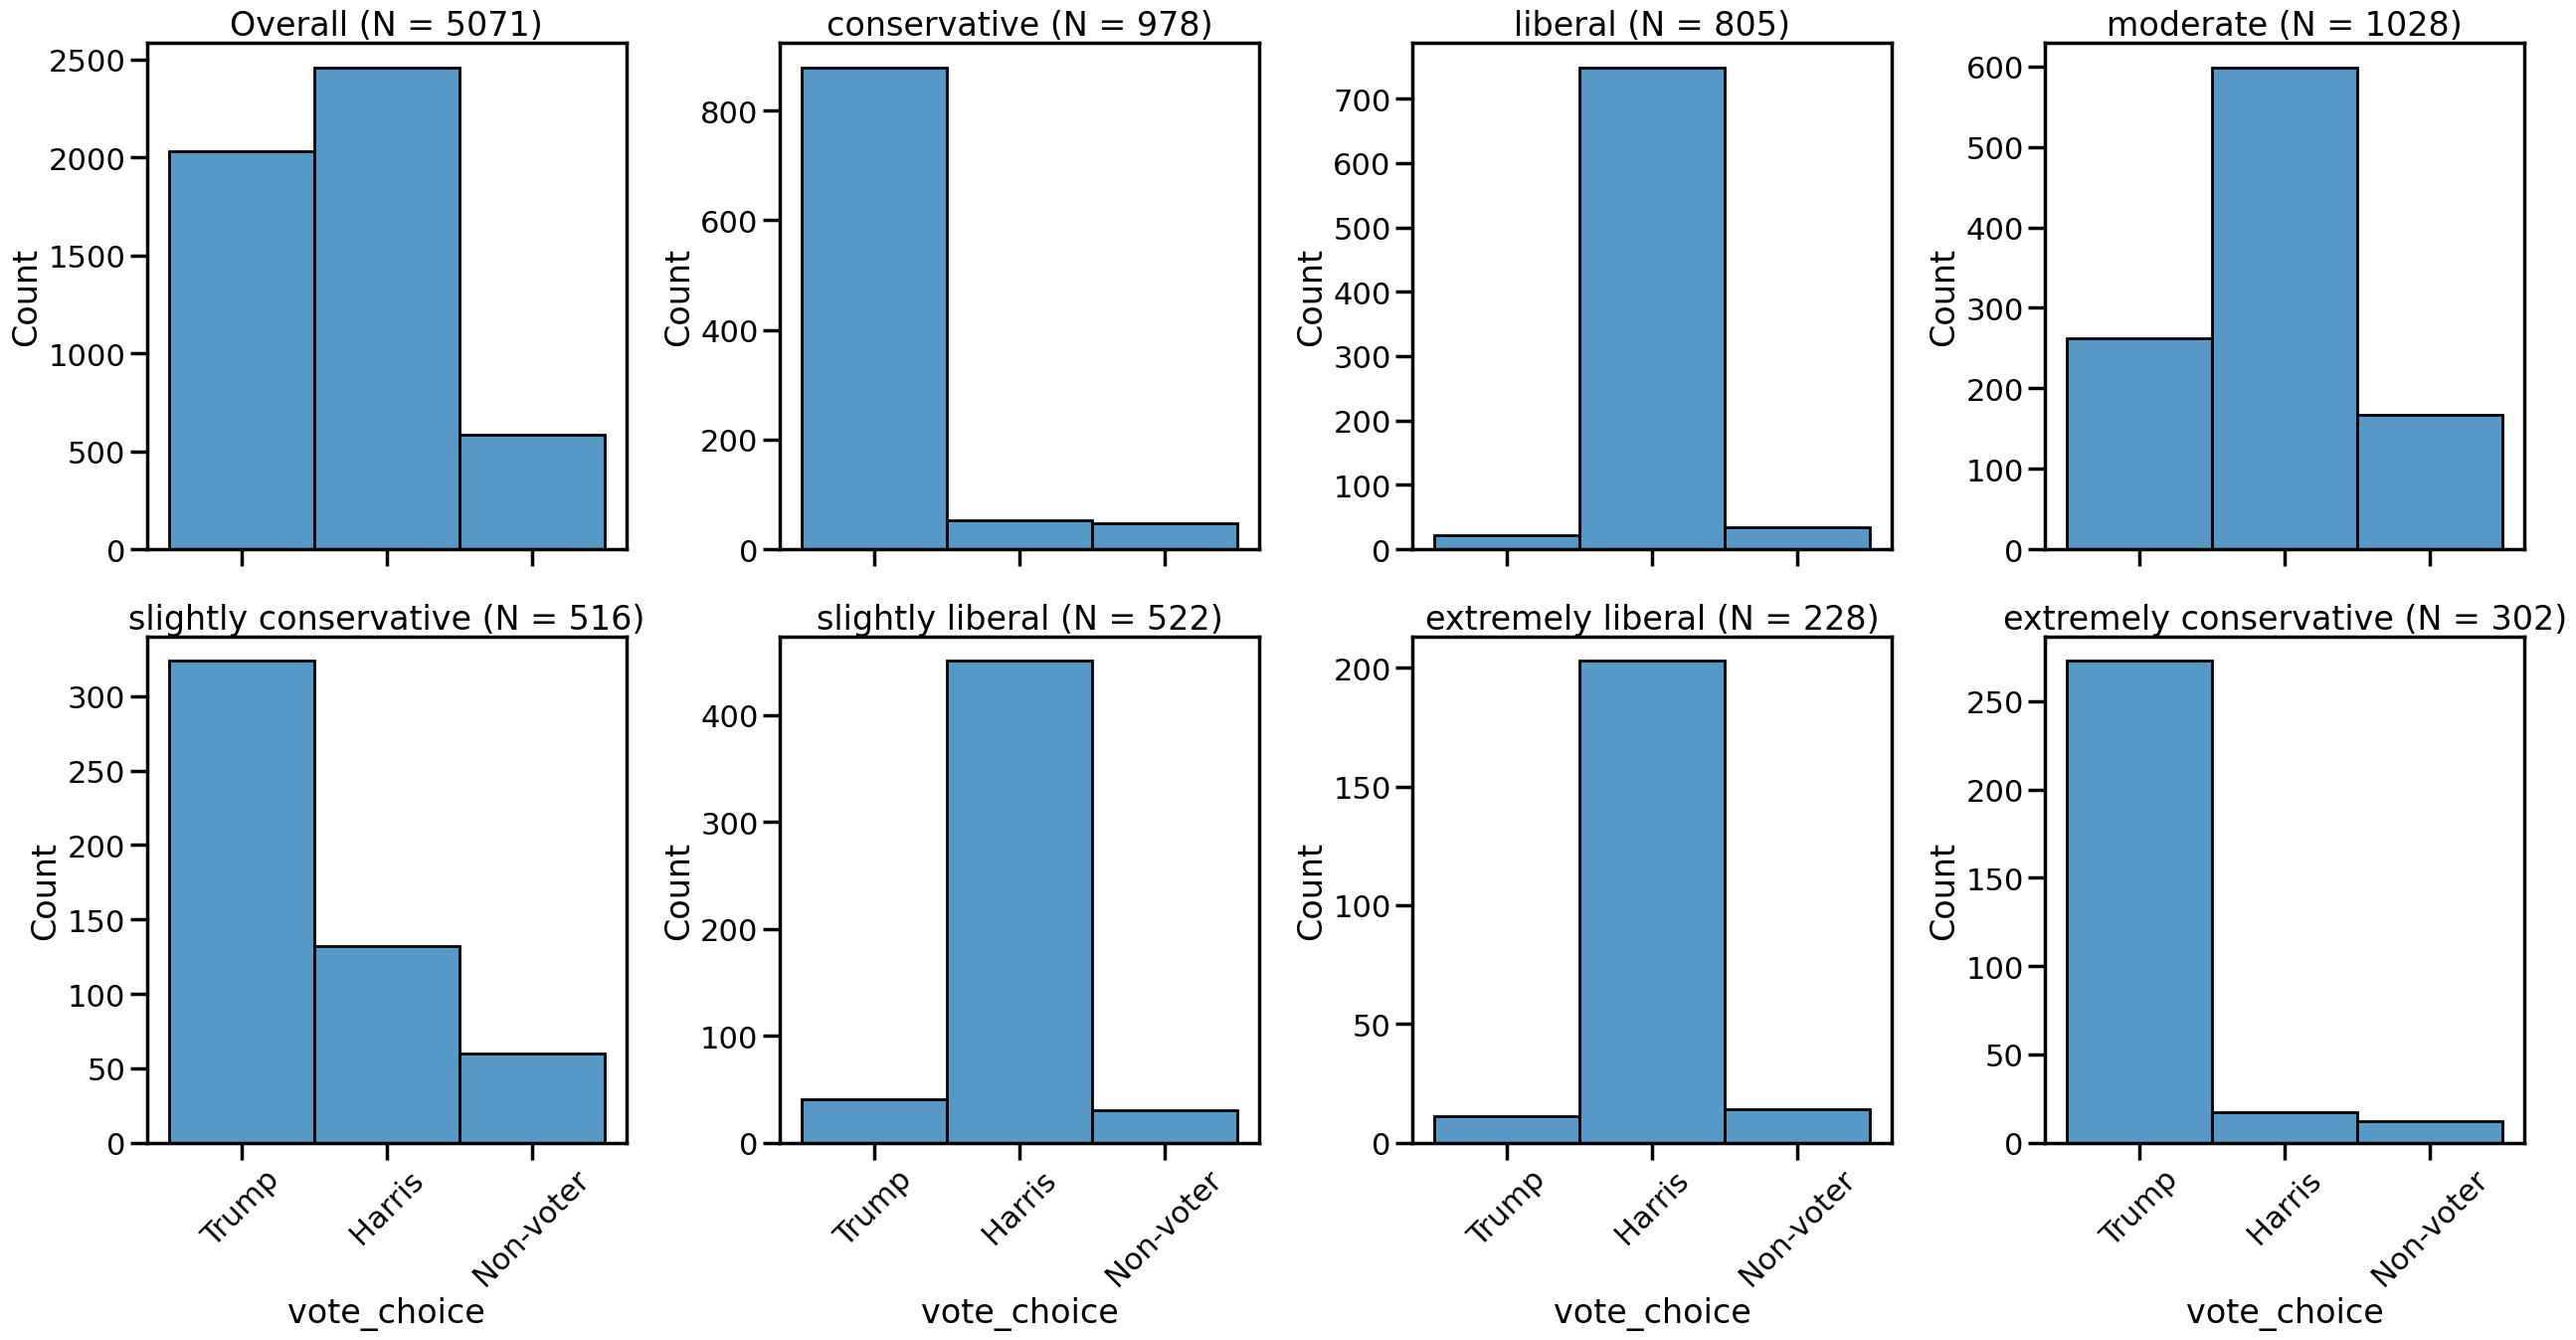

In [40]:
for subgroup_category in ['ideology']:
    subgroups = anes_df[subgroup_category].unique()
    # drop nan
    subgroups = [i for i in subgroups if type(i) == str]
    
    fig, axes = plt.subplots(2, 4, figsize=(26, 14), sharex = True, sharey = False)
    axes = axes.flatten()  # makes it easy to index axes[0], axes[1], ...
    
    # first subplot for all data
    sns.histplot(anes_df['vote_choice'], ax=axes[0])
    axes[0].set_title(f'Overall (N = {len(anes_df)})')
    axes[0].tick_params(axis='x', rotation=45)
    
    for i, subgroup in enumerate(subgroups):
        subgroup_df = anes_df[anes_df[subgroup_category] == subgroup]
        sns.histplot(subgroup_df['vote_choice'], ax=axes[i+1])
        axes[i+1].set_title(f'{subgroup} (N = {len(subgroup_df)})')
        axes[i+1].tick_params(axis='x', rotation=45)
    
    
    plt.tight_layout()
    plt.show()

In [41]:
# for each group and for each LLM, get the mean and std of vote choice across the candidates
grouped_llm_dfs = pd.DataFrame(plot_df.groupby(['LLM', 'parsed_answer']).size().unstack()).reset_index()
grouped_llm_dfs['group'] = 'Overall'

for subgroup_category in ['ideology']:
    subgroups = anes_df[subgroup_category].unique()
    # drop nan
    subgroups = [i for i in subgroups if type(i) == str]
    
    for group in subgroups:
        subgroup_df = plot_df[plot_df[subgroup_category] == group]
        grouped_llm_df = pd.DataFrame(subgroup_df.groupby(['LLM', 'parsed_answer']).size().unstack()).reset_index()
        grouped_llm_df['group'] = group
        grouped_llm_dfs = pd.concat([grouped_llm_dfs, grouped_llm_df])

In [42]:
anes_df[subgroup_category].unique()

array(['conservative', 'liberal', nan, 'moderate',
       'slightly conservative', 'slightly liberal', 'extremely liberal',
       'extremely conservative'], dtype=object)

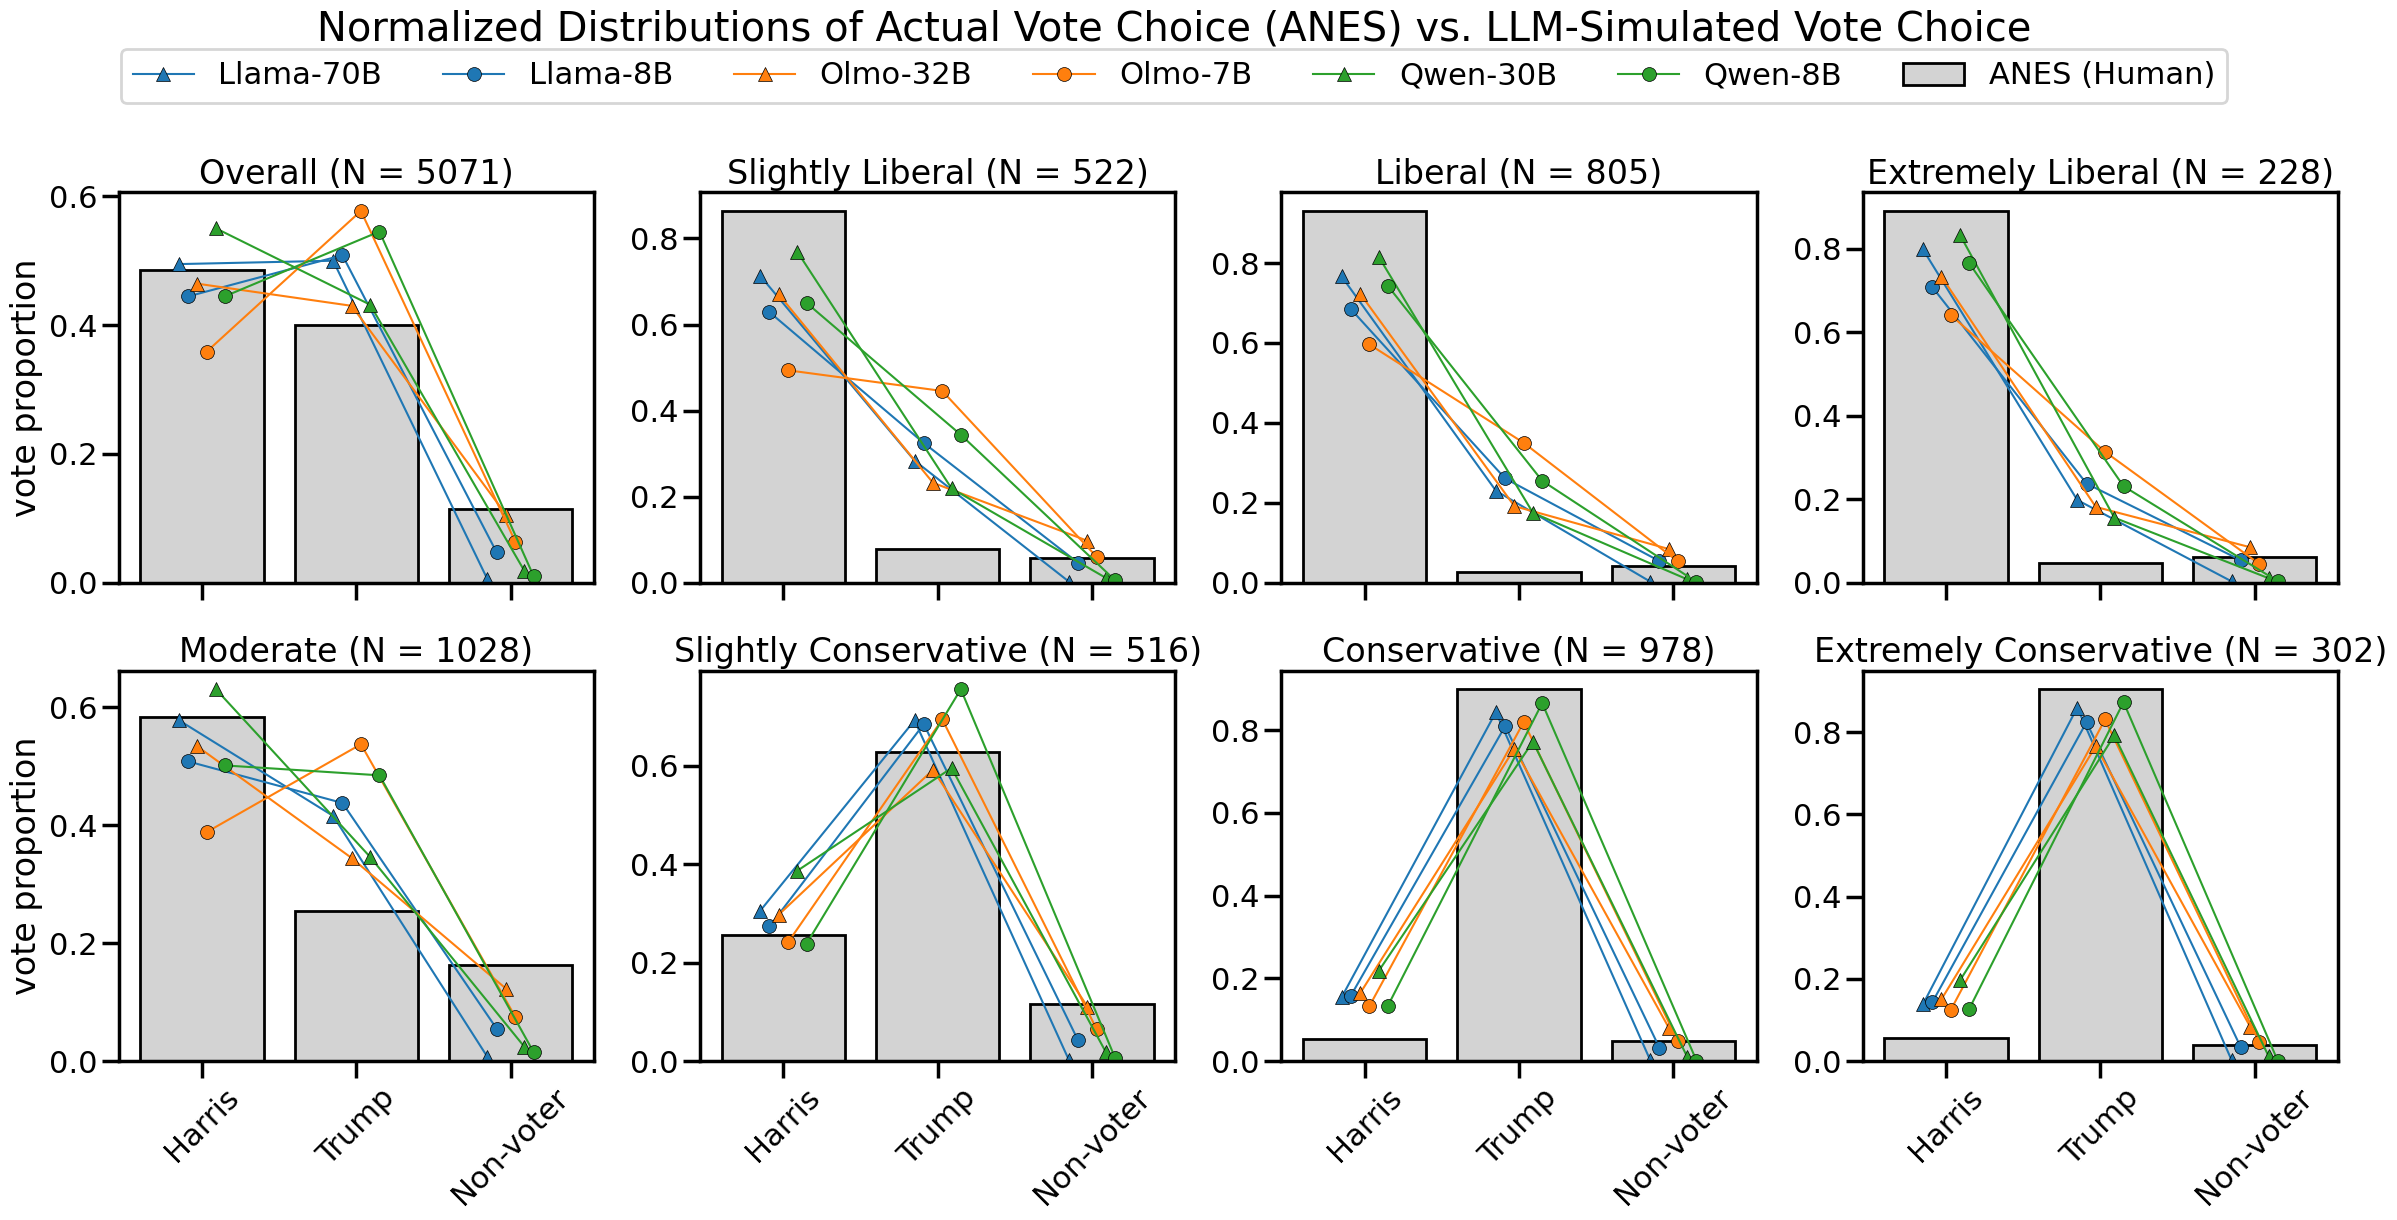

In [43]:
vote_categories = ['Harris', 'Trump', 'Non-voter']  # adjust to match your vote_choice labels
x_positions = np.arange(len(vote_categories))  # [0, 1, 2]

# --- build family/size mappings from the LLM names ---
llm_names = grouped_llm_dfs['LLM'].unique()

def parse_llm_name(name):
    family, size = name.split('-')  # e.g. 'Llama-70B' -> ('Llama', '70B')
    return family, size

def parse_size_num(size):
    return int(size.replace('B', ''))

families = sorted(set(parse_llm_name(n)[0] for n in llm_names))

color_palette = plt.cm.tab10.colors  # up to 10 distinct colors
marker_shapes = ['o', '^', 's', 'D', 'v', 'P', 'X', '*']  # rank 0 = smaller model, rank 1 = bigger model, etc.

family_to_color = {fam: color_palette[i % len(color_palette)] for i, fam in enumerate(families)}

# within each family, rank sizes smallest -> largest, so "smaller" always gets marker_shapes[0]
# and "bigger" always gets marker_shapes[1], regardless of the exact number (7B vs 8B, 30B vs 32B, etc.)
family_size_to_marker = {}
family_sizes = {}
for n in llm_names:
    fam, sz = parse_llm_name(n)
    family_sizes.setdefault(fam, set()).add(sz)

for fam, szs in family_sizes.items():
    sorted_szs = sorted(szs, key=parse_size_num)
    for rank, sz in enumerate(sorted_szs):
        family_size_to_marker[(fam, sz)] = marker_shapes[rank % len(marker_shapes)]

for subgroup_category in ['ideology']:
    subgroups = ['slightly liberal', 'liberal', 'extremely liberal', 'moderate', 
       'slightly conservative', 'conservative', 'extremely conservative']
    
    fig, axes = plt.subplots(2, 4, figsize=(24, 12), sharex = True)
    axes = axes.flatten()
    
    # first subplot for all data
    human_props = (
            anes_df['vote_choice']
            .value_counts(normalize=True)
            .reindex(vote_categories, fill_value=0)
    )
        
    axes[0].bar(x_positions, human_props.values, color='lightgray', edgecolor='black',
               label='ANES (Human)')
    # axes[i].set_yscale('log')
    axes[0].set_title(f'Overall (N = {len(anes_df)})')
    
    # --- overlay normalized LLM lines with dodge ---
    llm_subset = grouped_llm_dfs[grouped_llm_dfs['group'] == 'Overall']
    n_llms = len(llm_subset)
    dodge_width = 0.3  # total spread across all LLMs; tweak to taste
        
    for j, (_, row) in enumerate(llm_subset.iterrows()):
        counts = row[vote_categories].astype(float)
        proportions = counts / counts.sum()
        
        family, size = parse_llm_name(row['LLM'])
            
        # spread each LLM's line evenly around the category center
        offset = (j - (n_llms - 1) / 2) * (dodge_width / max(n_llms - 1, 1))
            
        axes[0].plot(
                x_positions + offset, proportions,
                marker=family_size_to_marker[(family, size)],
                color=family_to_color[family],
                label=row['LLM'],
                linewidth=1.5,
                markersize=10,
                markeredgecolor='black',
                markeredgewidth=0.5
            )
        
        axes[0].set_xticks(x_positions)
        axes[0].set_xticklabels(vote_categories, rotation=45)
    
    axes[0].set_ylabel('vote proportion')
    
    # repeat for subgroups
    for i, subgroup in enumerate(subgroups):
        subgroup_df = anes_df[anes_df[subgroup_category] == subgroup]
        
        # --- manually compute human proportions in a FIXED category order ---
        human_props = (
            subgroup_df['vote_choice']
            .value_counts(normalize=True)
            .reindex(vote_categories, fill_value=0)
        )
        
        axes[i+1].bar(x_positions, human_props.values, color='lightgray', edgecolor='black',
                     label='ANES (Human)')
        # axes[i].set_yscale('log')
        axes[i+1].set_title(f'{subgroup.title()} (N = {len(subgroup_df)})')
        
        # --- overlay normalized LLM lines with dodge ---
        llm_subset = grouped_llm_dfs[grouped_llm_dfs['group'] == subgroup]
        n_llms = len(llm_subset)
        dodge_width = 0.3  # total spread across all LLMs; tweak to taste
        
        for j, (_, row) in enumerate(llm_subset.iterrows()):
            counts = row[vote_categories].astype(float)
            proportions = counts / counts.sum()
            
            family, size = parse_llm_name(row['LLM'])
            
            # spread each LLM's line evenly around the category center
            offset = (j - (n_llms - 1) / 2) * (dodge_width / max(n_llms - 1, 1))
            
            axes[i+1].plot(
                x_positions + offset, proportions,
                marker=family_size_to_marker[(family, size)],
                color=family_to_color[family],
                label=row['LLM'],
                linewidth=1.5,
                markersize=10,
                markeredgecolor='black',
                markeredgewidth=0.5
            )
        
        axes[i+1].set_xticks(x_positions)
        axes[i+1].set_xticklabels(vote_categories, rotation=45)
        
        if i+1 == 4:
            axes[i+1].set_ylabel('vote proportion') 
    
    
    fig.suptitle('Normalized Distributions of Actual Vote Choice (ANES) vs. LLM-Simulated Vote Choice', y = 1.03)
    
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.01), ncol=len(labels))
    
    
    plt.tight_layout()
    plt.savefig(f'results/pre_election/persona_simulation_error_ideology.pdf')

In [44]:
anes_df[anes_df['ideology'].isna()]['vote_choice'].value_counts()

vote_choice
Harris       257
Non-voter    218
Trump        217
Name: count, dtype: int64

In [45]:
no_ideology = plot_df[plot_df['ideology'].isna()]
print(classification_report(no_ideology['vote_choice'], no_ideology['parsed_answer'],
                           zero_division=0))

              precision    recall  f1-score   support

      Harris       0.55      0.74      0.63    185040
   Non-voter       0.55      0.12      0.19    156960
       Trump       0.49      0.66      0.56    156240
         nan       0.00      0.00      0.00         0

    accuracy                           0.52    498240
   macro avg       0.40      0.38      0.34    498240
weighted avg       0.53      0.52      0.47    498240



In [46]:
(49 + 42 + 23) / 4

28.5

In [47]:
len(no_ideology)

498240

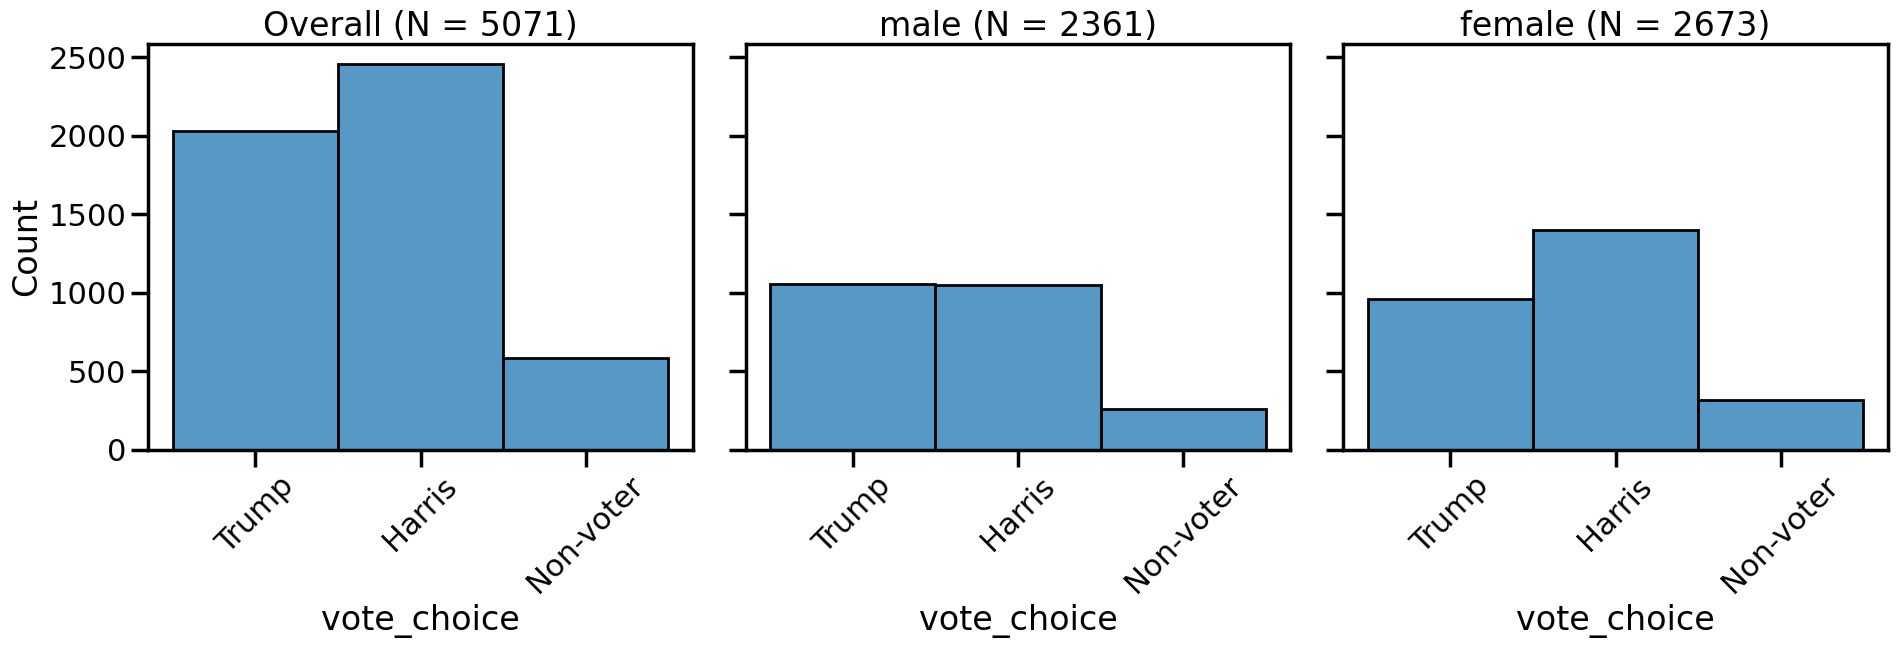

In [48]:
for subgroup_category in ['gender']:
    subgroups = anes_df[subgroup_category].unique()
    # drop nan
    subgroups = [i for i in subgroups if type(i) == str]
    
    fig, axes = plt.subplots(1, len(subgroups) + 1, figsize=(6.5 * (len(subgroups) + 1), 7), sharex = True, sharey = True)
    axes = axes.flatten()  # makes it easy to index axes[0], axes[1], ...
    
    # first subplot for all data
    sns.histplot(anes_df['vote_choice'], ax=axes[0])
    axes[0].set_title(f'Overall (N = {len(anes_df)})')
    axes[0].tick_params(axis='x', rotation=45)
    
    for i, subgroup in enumerate(subgroups):
        subgroup_df = anes_df[anes_df[subgroup_category] == subgroup]
        sns.histplot(subgroup_df['vote_choice'], ax=axes[i+1])
        axes[i+1].set_title(f'{subgroup} (N = {len(subgroup_df)})')
        axes[i+1].tick_params(axis='x', rotation=45)
    
    
    plt.tight_layout()
    plt.show()